Epoch 1/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8004 - val_loss: 0.7283
Epoch 2/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6244 - val_loss: 0.6089
Epoch 3/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5376 - val_loss: 0.5536
Epoch 4/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5047 - val_loss: 0.5364
Epoch 5/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4881 - val_loss: 0.5247
Epoch 6/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4732 - val_loss: 0.5140
Epoch 7/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4631 - val_loss: 0.5072
Epoch 8/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4566 - val_loss: 0.5006
Epoch 9/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4505 - val_loss: 0.4975
Epoch 10/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4448 - val_loss: 0.4890
8901/8901 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
Accuracy: 95.11634194384267 %


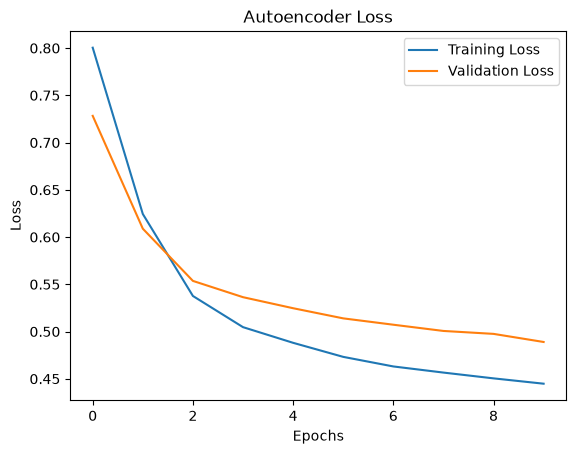

In [1]:

# 1. Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# STEP 1: Load dataset
data = pd.read_csv("creditcard.csv")

# Separate normal transactions
normal_data = data[data["Class"] == 0]

# Separate features and labels
X = data.drop("Class", axis=1).values
y = data["Class"].values

# Use only normal transactions for training
x_train = normal_data.drop("Class", axis=1).values

# Normalize data
mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
std[std == 0] = 1

x_train = (x_train - mean) / std
X = (X - mean) / std

# STEP 2: Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),

    # Encoder
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),

    # Decoder
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(X.shape[1], activation='linear')
])

# Compile model
model.compile(optimizer='adam', loss='mse')

# STEP 3: Train model
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2
)

# STEP 4: Detect fraud

# Reconstruct transactions
reconstructed = model.predict(X)

# Calculate reconstruction error
errors = np.mean(np.square(X - reconstructed), axis=1)

# Set threshold
threshold = np.percentile(errors, 95)

# Predict fraud
predictions = (errors > threshold).astype(int)

# STEP 5: Evaluate model

accuracy = np.mean(predictions == y)

print("Accuracy:", accuracy * 100, "%")

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


# Practical 3A – Credit Card Fraud Detection Using Autoencoder

## Problem statement

3A. Implement credit card fraud detection for given credit card fraud detection Kaggle dataset using Autoencoder and build the model using the following steps:

- Preprocess the data by scaling features (features are already PCA-transformed, so they’re anonymized).
- Train an autoencoder on non-fraudulent transactions to learn typical spending patterns.
- Calculate reconstruction errors for transactions and set a threshold to detect fraud.
- Compile the models with Optimizer, Loss, and Evaluation Metrics.

Medium difficulty

## 1. Understand the practical

What is credit card fraud detection?

It means identifying whether a credit card transaction is genuine or fraudulent.

For example:

- Normal transaction: You purchase something for ₹500.
- Fraudulent transaction: Someone uses your card without permission.

The dataset contains two types of transactions:

| Class value | Meaning                |
| ----------- | ---------------------- |
| 0           | Normal transaction     |
| 1           | Fraudulent transaction |

Important: The dataset is highly imbalanced. There are many normal transactions but very few fraudulent transactions.

### What is an Autoencoder?

An Autoencoder is a type of neural network that learns to compress data and then reconstruct it.

In this practical:

- We train the model using only normal transactions.
- It learns the patterns of normal transactions.
- When it receives an unusual fraudulent transaction, it may reconstruct it poorly.
- A large reconstruction error can indicate fraud.

[Unsupervised Anomaly Detection on Credit Card Fraud | by Aishwarya Rajeev | Medium](https://images.openai.com/static-rsc-4/0i9PrzM2zTDn_W3TVJVt7LuiQG3pcXiFjDwjzfnJnY1oOO1YVHyMODrH4J0UP0pfLtiDlTvcgWmtXgLHK4oueab3rp6HGdp3QmWDTmWijSxdfaATQVD6i9VEwIqwsdjIfYmajA0CWTHh7U5auW-BN_KYrzmBZ0eYqOTQ4Bgi6v8?purpose=inline)

[medium.com](https://medium.com/%40aishwaryarajeev_68039/unsupervised-anomaly-detection-on-credit-card-fraud-3e9c8802fd01?utm_source=chatgpt.com)

Think of it like this:

Normal transaction → Small reconstruction error

Unusual transaction → Potentially large reconstruction error

## 2. Stage 1 – Load and preprocess data

### Import libraries

```
import pandas as pdimport numpy as npimport tensorflow as tfimport matplotlib.pyplot as plt
```

| Library    | Purpose                |
| ---------- | ---------------------- |
| Pandas     | Load CSV data          |
| NumPy      | Numerical calculations |
| TensorFlow | Build autoencoder      |
| Matplotlib | Plot loss graph        |

### Load dataset

```
data = pd.read_csv("creditcard.csv")
```

Loads the Kaggle credit card dataset.

### Separate normal transactions

```
normal_data = data[data["Class"] == 0]
```

This selects only normal transactions.

Why?

Because our objective is to teach the autoencoder what normal transactions look like.

### Separate features and labels

```
X = data.drop("Class", axis=1).valuesy = data["Class"].values
```

- `X`: All transaction features.
- `y`: Actual transaction labels (0 or 1).

```
x_train = normal_data.drop("Class", axis=1).values
```

`x_train` contains only normal transactions, which will be used for training.

### Normalize data

```
mean = x_train.mean(axis=0)std = x_train.std(axis=0)std[std == 0] = 1
```

- `mean`: Average value of each feature.
- `std`: Standard deviation of each feature.
- `std == 0`: Handles features with zero variation to avoid division by zero.

```
x_train = (x_train - mean) / stdX = (X - mean) / std
```

This is called standardization.

It transforms features approximately to a mean of 0 and standard deviation of 1, using statistics from normal training transactions.

Why normalize?

Features may have different ranges. Scaling helps the neural network learn more effectively.

## 3. Stage 2 – Build Autoencoder

Your model:

Input layer

All transaction features

Encoder – Dense 16

Compresses information

Bottleneck – Dense 8

Compressed representation

Decoder – Dense 16

Reconstructs information

Output layer

Reconstructed transaction features

### Create model

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(X.shape[1],)),    # Encoder    tf.keras.layers.Dense(16, activation='relu'),    tf.keras.layers.Dense(8, activation='relu'),    # Decoder    tf.keras.layers.Dense(16, activation='relu'),    tf.keras.layers.Dense(X.shape[1], activation='linear')])
```

Understand the important lines:

Input layer

```
tf.keras.layers.Input(shape=(X.shape[1],))
```

Accepts all transaction features.

In the standard Kaggle dataset, there are 30 input features:

- Time
- V1 to V28 (PCA-transformed features)
- Amount

The `Class` column is excluded.

Encoder

```
tf.keras.layers.Dense(16, activation='relu'),tf.keras.layers.Dense(8, activation='relu'),
```

The encoder compresses the transaction information:

- First layer: 16 neurons.
- Bottleneck layer: 8 neurons.

Decoder

```
tf.keras.layers.Dense(16, activation='relu'),tf.keras.layers.Dense(X.shape[1], activation='linear')
```

The decoder tries to reconstruct the original transaction.

The output has the same number of features as the input.

What is linear activation?

Linear activation returns the input value without applying a nonlinear transformation. It is useful for reconstructing numerical feature values.

### Compile model

```
model.compile(optimizer='adam', loss='mse')
```

- Adam: Optimizer that updates model weights.
- MSE: Mean Squared Error, measures the difference between original and reconstructed transactions.

Important: This code does not specify an evaluation metric in `compile()`. It uses loss for training and calculates accuracy manually later.

## 4. Stage 3 – Train the model

```
history = model.fit(    x_train, x_train,    epochs=10,    batch_size=256,    validation_split=0.2)
```

Notice something important:

```
x_train, x_train
```

Why are both inputs and outputs the same?

Because an autoencoder tries to reconstruct its own input.

| Parameter              | Meaning                                        |
| ---------------------- | ---------------------------------------------- |
| `x_train`              | Normal transactions                            |
| Second `x_train`       | Expected reconstructed output                  |
| `epochs=10`            | Train for 10 complete passes                   |
| `batch_size=256`       | Process 256 transactions per batch             |
| `validation_split=0.2` | Use 20% of normal training data for validation |

The model learns to reconstruct normal transactions accurately.

## 5. Stage 4 – Detect fraud

This is the most important part of the practical.

### Reconstruct transactions

```
reconstructed = model.predict(X)
```

The trained autoencoder tries to reconstruct every transaction, including normal and fraudulent transactions.

### Calculate reconstruction error

```
errors = np.mean(np.square(X - reconstructed), axis=1)
```

This calculates the average squared difference between the original and reconstructed features for each transaction.

The formula is:

\\[ MSE=\frac{1}{n}\sum\_{i=1}^{n}(X_i-\hat X_i)^2 \\]

- \\(X_i\\): Original feature.
- \\(\hat X_i\\): Reconstructed feature.
- \\(n\\): Number of features.

Remember:

- Small error → Model reconstructed the transaction well.
- Large error → Transaction may be unusual.

### Set threshold

```
threshold = np.percentile(errors, 95)
```

This selects the 95th percentile of reconstruction errors.

In simple words, it uses the error value below which 95% of transaction errors fall.

### Predict fraud

```
predictions = (errors > threshold).astype(int)
```

This is the fraud detection condition:

- If error is greater than threshold → Predict 1 (fraud).
- Otherwise → Predict 0 (normal).

`astype(int)` converts True/False into 1/0.

## 6. Evaluate model performance

```
accuracy = np.mean(predictions == y)print("Accuracy:", accuracy * 100, "%")
```

This compares predicted labels with actual labels.

However, there is an important limitation in your code:

Accuracy alone is not sufficient for fraud detection.

Because the dataset is highly imbalanced, a model could predict nearly every transaction as normal and still achieve very high accuracy.

Better evaluation measures include:

- Precision: Out of all transactions predicted as fraud, how many were actually fraud?
- Recall: Out of all actual fraudulent transactions, how many did the model detect?
- F1-score: Balance between precision and recall.
- Confusion matrix: Shows correct and incorrect predictions.

For your practical, you can add this simple evaluation:

```
from sklearn.metrics import classification_report, confusion_matrixprint(confusion_matrix(y, predictions))print(classification_report(y, predictions))
```

What is the confusion matrix?

It shows:

| Term           | Meaning                            |
| -------------- | ---------------------------------- |
| True Positive  | Fraud correctly detected           |
| True Negative  | Normal correctly detected          |
| False Positive | Normal incorrectly marked as fraud |
| False Negative | Fraud missed by the model          |

### Plot training loss

```
plt.plot(history.history['loss'], label='Training Loss')plt.plot(history.history['val_loss'], label='Validation Loss')plt.title("Autoencoder Loss")plt.xlabel("Epochs")plt.ylabel("Loss")plt.legend()plt.show()
```

This graph shows whether the autoencoder is learning to reconstruct normal transactions.

Ideally, training and validation loss decrease.

## 7. Important viva questions

| Question                                    | Answer                                                                                                    |
| ------------------------------------------- | --------------------------------------------------------------------------------------------------------- |
| What is an Autoencoder?                     | A neural network that learns to compress and reconstruct data.                                            |
| Why use an Autoencoder for fraud detection? | It learns normal transaction patterns and can identify unusual transactions through reconstruction error. |
| What is an Encoder?                         | Compresses input information.                                                                             |
| What is a Decoder?                          | Reconstructs the original input.                                                                          |
| What is a Bottleneck?                       | The smallest compressed representation in the model.                                                      |
| Why train only on normal transactions?      | So the model learns typical normal transaction patterns.                                                  |
| What is reconstruction error?               | Difference between original and reconstructed data.                                                       |
| What is a threshold?                        | A boundary used to classify transactions as normal or suspicious.                                         |
| What is MSE?                                | Mean Squared Error, measures reconstruction difference.                                                   |
| What is PCA?                                | Principal Component Analysis, a dimensionality-reduction technique.                                       |
| Why is the dataset imbalanced?              | Fraudulent transactions are much fewer than normal transactions.                                          |
| What is an epoch?                           | One complete pass through training data.                                                                  |
| What is overfitting?                        | Model learns training data too closely and performs poorly on unseen data.                                |

## 8. Short explanation for the examiner

"In this practical, I implemented credit card fraud detection using an Autoencoder.

First, I loaded the credit card dataset and separated normal transactions from fraudulent transactions. I used only normal transactions for training and standardized the features.

Then, I created an Autoencoder with an Encoder containing 16 and 8 neurons and a Decoder containing 16 neurons and an output layer.

I compiled the model using Adam optimizer and Mean Squared Error loss. I trained it for 10 epochs using a batch size of 256.

After training, I reconstructed all transactions and calculated reconstruction errors. I selected the 95th percentile as the threshold. Transactions with errors greater than the threshold were classified as fraudulent.

Finally, I compared predictions with actual labels and plotted the training and validation loss."

## 9. Quick revision

| Parameter        | Value                        |
| ---------------- | ---------------------------- |
| Dataset          | Credit Card Fraud            |
| Training data    | Normal transactions only     |
| Input features   | 30                           |
| Encoder          | 16 → 8                       |
| Decoder          | 16 → 30                      |
| Optimizer        | Adam                         |
| Loss             | MSE                          |
| Epochs           | 10                           |
| Batch size       | 256                          |
| Validation       | 20%                          |
| Threshold        | 95th percentile              |
| Fraud prediction | Error greater than threshold |

Three things you must remember for this practical:

1. Autoencoder is trained only on normal transactions.
2. Reconstruction error is used to identify unusual transactions.
3. Threshold decides whether a transaction is classified as fraud.

Technical note: The 95th-percentile threshold in your code is calculated using all transactions, including the test/fraud examples. It is a simple practical demonstration, not a fully reliable deployment method. For a fair evaluation, choose the threshold using a separate normal validation set and evaluate on held-out transactions.